In [244]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import gamma

### Initial parameters and functions from QCD theory ###

In [245]:
uv_p0 = np.array([2.27296347428, -0.5, 3.3, 0]) #np.array([3.71148178, -0.39539093,  3.52377563, -0.39854316])
ub_p0 = np.array([0.13, -1.266, 5.6, 0]) #np.array([0.136, -1.264, 3, -0.6])
dv_p0 = np.array([1.13648173714, -0.5, 3.3, 0]) #np.array([1.41487772151, -0.5, 4.4, -0.39854316])
db_p0 = np.array([0.13, -1.266, 5.6, 0]) #np.array([0.136, -1.264, 3, -0.6])
kappa = 0.5

initParams = np.array([uv_p0, ub_p0, dv_p0, db_p0], dtype=np.float64)

def f(x, params):
    return params[0]*x**(params[1]) * (1-x)**(params[2]) * (1 + (params[3])*np.sqrt(x))

def F2(x, paramsMatrix):
    uv_params = paramsMatrix[0]
    ub_params = paramsMatrix[1]
    dv_params = paramsMatrix[2]
    db_params = paramsMatrix[3]
    return x*((4/9)*(f(x, uv_params) + 2*f(x, ub_params)) +
              (1/9)*(f(x, dv_params) + 2*f(x, db_params)) +
              (1/9)*kappa*(f(x, ub_params)+f(x, db_params))
              )

def F21D(x, params):
    uv_params = params[0:4]
    ub_params = params[4:8]
    dv_params = params[8:12]
    db_params = params[12:16]
    return x*((4/9)*(f(x, uv_params) + 2*f(x, ub_params)) +
              (1/9)*(f(x, dv_params) + 2*f(x, db_params)) +
              (1/9)*kappa*(f(x, ub_params)+f(x, db_params))
              )

### Algorithms ####

Trapezoid rule numerical integration

In [246]:
#Define a function for trapezoid rule integration
def Int_trap(func, a, b, h=0.1, args=()):
    N = int(round((b-a)/h)) + 1 #Number of steps corresponding to h
    x_list = np.linspace(a, b, N) #List of discretized x-values
    F = func(x_list, *args)
    
    #Integrate over x using the trapezoid rule
    return h/2*((F[0]+F[-1])+2*np.sum(F[1:-1]))

#Trapezoid rule integration with automatically chosen h
def Integrate(func, a, b, h=0.1, cutoff=1e-8, args=()):
    I1 = Int_trap(func, a, b, h, args) #Initial integration value
    I_diff = 1 #Assume an initial nonzero difference greater than the cutoff
    #Loop the algorithm until the difference in the evaluated integrals is within the cutoff
    while(I_diff >= cutoff):
        h = h/2 #Halve h with each iteration
        I2 = Int_trap(func, a, b, h, args) #Evaluate a second integral I2 to compare I1 to
        I_diff = abs(I2 - I1) #Take the difference between I1 and I2

        #If the difference is within the cutoff, return I2.
        #Else, set I1 to I2 and repeat the calculation
        if I_diff < cutoff:
            I = I2
        else:
            I1 = I2

    return I

from scipy.integrate import quad
def Integrate(func, a, b, args=()):
    return quad(func, a, b, args=args)[0]

Gradient descent

In [247]:
#Finite difference perturbation
def perturb(params, i, h, j=None, step2 = False):
    if len(params.shape) == 1:
        pplus = np.copy(params)
        pplus[i] += h
        pminus = np.copy(params)
        pminus[i] -= h
        if step2:
            p2plus = np.copy(params)
            p2plus[i] += 2*h
            p2minus = np.copy(params)
            p2minus[i] -= 2*h

    if len(params.shape) == 2:
        pplus = np.copy(params)
        pplus[i,j] += h
        pminus = np.copy(params)
        pminus[i,j] -= h
        if step2:
            p2plus = np.copy(params)
            p2plus[i,j] += 2*h
            p2minus = np.copy(params)
            p2minus[i,j] -= 2*h
    
    if step2:
        return pplus, pminus, p2plus, p2minus
    else:
        return pplus, pminus

#Gradient of the parameters
def grad(func, x, params, fixedParams=[]):
    gradient = np.zeros(params.shape)
    h = (np.finfo(np.float64).eps)**(1/3) #Optimal step size for central difference

    fixedIndices = []
    if len(fixedParams) != 0:
        for fix in fixedParams:
            fixedIndices.append(fix[0])

    for i in range(len(params)):
        if len(params.shape) == 1:
            pplus, pminus, p2plus, p2minus = perturb(params, i, h, step2=True)

            if i in fixedIndices:
                gradient[i] = 0
            else:
                try:
                    gradient[i] = (-func(x, p2plus) + 8*func(x, pplus) - 8*func(x, pminus) + func(x, p2minus)) / (12*h)
                except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                    pass

        if len(params.shape) == 2:
            for j in range(params.shape[1]):
                pplus, pminus, p2plus, p2minus = perturb(params, i, h, j=j, step2=True)

                if (i,j) in fixedIndices:
                    gradient[i,j] = 0
                else:
                    try:
                        gradient[i,j] = (-func(x, p2plus) + 8*func(x, pplus) - 8*func(x, pminus) + func(x, p2minus)) / (12*h)
                    except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                        pass

    return gradient

#Gradient Descent Algorithm
#Parameters: Cost function 'func', x, initial parameters 'initParams'.
#Optional: step size 'eta', maximum number of iterations 'maxit', and tolerance 'tol'
def grdsc(func, x, initParams, eta=1e-3, beta1=0.9, maxit=100000, costTol=1e-8, gradTol=1e-8, fixedParams=[], conds=[]):
    #Initialize the parameters
    params_prev = np.copy(initParams)
    m = 0
    converged = False #Define a boolean for checking whether or not convergence is met.

    #Implement the gradient descent algorithm until convergence or until the maximum
    #number of iterations has been met
    for i in range(maxit):
        gradient = grad(func, x, params_prev, fixedParams)
        m = beta1*m + (1-beta1)*gradient
        m_hat = m/(1-beta1**(i+1))
        params = params_prev - eta*m_hat

        #Enforce any constraint conditions on the parameters (e.g. a1 > 0).
        #'conds' stores [constraint function (e.g. params[:1] > 0), 
        #index of the column corresponding to the parameter that the constraint is on (e.g. 1)]
        for cond in conds:
            #Determine the boolean array discerning whether or not the condition has been violated for a given
            #parameter in a 1D parameter array or a column of parameters in a 2D parameter array
            notCond = ~(cond[0](params))
            #If the condition is violated, find the offending parameters and revert them to their previous values.
            #In the case that the parameters are stored as a 2D array, we need to find the rows of the offending
            #parameters, which then allows us to locate them given the column that the condition is placed on.
            if notCond.any():
                if len(np.shape(params)) == 2: #If we have a 2D array of parameters
                    for k in np.where(notCond)[0]:
                        params[k, cond[1]] = params_prev[k, cond[1]]

                elif len(np.shape(params)) == 1: #If we have a 1D array of parameters
                    params[cond[1]] = params_prev[cond[1]]

        #Fix any parameters with defined fixing conditions.
        #'fixedParams' stores [index of fixed parameter, fixing condition]
        if len(fixedParams) != 0:
            for fix in fixedParams:
                index = fix[0]
                condition = fix[1]
                params[index] = condition(params)

        cost = func(x, params)

        #If the parameters are close to their previous values up to some tolerance, then
        #convergence has been met and we can break out of the loop
        if (np.isclose(cost, 0, atol=costTol) or 
            np.isclose(grad(func, x, params, fixedParams), 0, atol=gradTol).all()):
            converged = True
            break

        #Else, set params_prev -> params and move on to the next iteration
        else:
            params_prev = params

    return params, cost, converged

Hessian matrix via finite-difference approximation

In [248]:
def hessian(func, x, params):
    dims = len(params.flatten())
    H = np.zeros((dims, dims))
    h = (np.finfo(np.float64).eps)**(1/4) #Optimal step size for second partial central difference
    for i in range(dims):
        for j in range(dims):
            if i == j:
                pplus, pminus = perturb(params, i, h, j=j)
                try:
                    H[i,j] = (func(x, pplus) - 2*func(x, params) + func(x, pminus)) / h**2
                except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                    pass

            else:
                pplus_i, pminus_i = perturb(params, i, h)
                plus_iPlus_j, plus_iMin_j = perturb(pplus_i, j, h)
                min_iPlus_j, min_iMin_j = perturb(pminus_i, j, h)
                try:
                    H[i,j] = ((func(x, plus_iPlus_j) - func(x, plus_iMin_j) -
                               func(x, min_iPlus_j) + func(x, min_iMin_j)) / (4*h**2))
                except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                    pass

    return H

QR diagonalization

In [249]:
#Gran Schmidt QR decomposition
def GSDecomp(M):
    m, n = M.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for k in range(len(M)):
        u = M[:,k].copy()
        for i in range(k):
            R_ik = u @ Q[:,i]
            u -= (R_ik)*Q[:,i]
            R[i, k] = R_ik

        Q[:,k] = u/np.linalg.norm(u)
        R[k,k] = np.linalg.norm(u)
    return Q, R

#QR algorithm
def diagonalize(M, maxit=500, tol=1e-8):
    A = M.copy()
    converged = False
    for i in range(maxit):
        Q, R = GSDecomp(A)
        A = R @ Q
        if np.sum(np.triu(A, 1)) / (len(A)*(len(A)-1)/2) <= tol:
            converged = True
            break
    
    return A, converged

Gauss-Jordan elimination

In [250]:
#Function for swapping the ith and jth rows of a given matrix A
def swap_ij(M,i,j):
    A = np.copy(M)
    tempRow = np.copy(A[j,:])
    A[j,:] = A[i,:]
    A[i,:] = tempRow
    return A

#Function for multiplying the ith row of A by a real number k
def M_i(M,i,k):
    A = np.copy(M)
    A[i,:] = A[i,:]*k
    return A

#Function for adding k times the ith row of A to the jth row of A
def add_ij(M,i,j,k):
    A = np.copy(M)
    A[j,:] += A[i,:]*k
    return A

#Function for swapping any row starting with 1 to the jth row
def SwapOne(M,j):
    A = np.copy(M)

    #Check if there are 1's in the jth column (excluding entries from any row before the
    #jth row). We specifically want to exclude previous rows so that as we put the matrix
    #into REF, we can limit row swapping to non-pivot rows, leaving any previous pivot
    #rows intact.

    #np.isin(A[j:n,j], 1) creates an array of booleans (which is interpreted as 1's and
    #0's using .astype(int)) stating whether or not there is a 1 in the A[j:n,j]
    #"sub-vector."
    listOnes = np.isin(A[j:len(A),j], 1).astype(int)

    #np.where(listOnes == 1)[0] extracts the indices of the 1's and stores them into an
    #array. Since the vector A[j:n,j] used to check for 1's is a "sub-vector" of the
    #entire jth column, we need to shift the indexing by +j so that the indices stored in
    #oneIndices line up with the rows of A
    oneIndices = np.where(listOnes == 1)[0] + j

    #If there are rows starting with 1 (i.e. oneIndices is non-empty), swap the first of
    #such rows with the jth row. We specifically want to swap with the jth row because as
    #we put the matrix into REF, the jth row becomes the top row of the (n-j, n-j)
    #sub-matrix that still needs to be put into REF.
    if np.size(oneIndices) != 0:
        #Pick the index of the first instance of a row starting w/ 1
        i1 = oneIndices[0]
        A = swap_ij(A,j,i1)
    
    return A

#Function for bringing all of the rows starting with 0 (within a given submatrix) to the
#bottom
def SwapZeros(M,j):
    A = np.copy(M)

    #Using the same method as SwapOne, we can find the indices of 0's (and non-zeros)
    #within the pivot column of a given (n-j, n-j) sub-matrix and then re-index those
    #indices so that they line up with the rows of the A matrix.
    listZeros = np.isin(A[j:len(A),j], 0).astype(int)
    zeroIndices = np.where(listZeros == 1)[0] + j
    non0Indices = np.where(listZeros == 0)[0] + j

    #If there are rows within the sub-matrix starting with 0 and if the row is not entirely
    #0's, swap the 0-rows with the lowest possible non-zero row.
    if np.size(zeroIndices) != 0 and np.size(zeroIndices) < len(A):
        z=0
        n0I = non0Indices

        if len(n0I) == 0:
            return A #If there are no non-zero indices to swap with, just return A as is
        
        for i0 in zeroIndices:
            #Let in0 be a list of the indices of the non-zero rows. The % operator is used
            #to avoid indexing out of bounds as z increases with each iteration. This will
            #result in in0 repeating the same set of indices, but this is fine since we can
            #check if in0 > z before swapping any rows.

            #As we put the matrix into REF, most of the non-zero rows will be the top rows of
            #the matrix, corresponding to low-valued indices like in0 = 0, 1, 2, ... As z
            #increases with each iteration of the loop, z will eventually become greater than
            #the indices of the non-zero rows (i.e. in0 < z for all possible values of in0),
            #preventing the algorithm from swapping 0-rows with any of the non-zero rows at
            #the top of the matrix.
            in0 = n0I[-(1+z)%len(n0I)]
            if i0 < len(A)-(1+z) and in0 > z:
                A = swap_ij(A,i0,in0)
            z+=1
            
    return A

#Function for "normalizing" a row (i.e. multiplying the row by some number so that its pivot
#entry equals 1)
def normalize(M,i):
    A = np.copy(M)
    if A[i,i] == 0:
        return A #If the pivot is 0, return A as is
    return M_i(A,i,1/A[i,i])

#Function for putting the matrix into REF (i.e. making it upper triangular)
def UpTri(A, tol=1e-6):
    n=len(A)
    #Following the basic procedure of Gauss' Jordan elimination, we can put the matrix into REF
    #by moving any existing pivot rows to the top, moving any 0-rows to the bottom, and then
    #adding multiples of each pivot row to each non-pivot row
    for j in range(n):
        A = SwapOne(A,j)
        A = SwapZeros(A,j)
        A = normalize(A,j)

        for i in range(j, n-1):
            if np.abs(A[i+1, j]) > tol:
                A = add_ij(A,j,i+1,-A[i+1,j]/A[j,j])

        A[np.abs(A) <= tol] = 0

    A = normalize(A,n-1)
    return A

def LoTri(A, tol=1e-6):
    n=len(A)
    if A[n-1, n-1] == 0: #If there are infinitely many solutions, choose the free parameter to be 1
        A[n-1, n-1] = 1
        A[n-1, n] = 1

    for i in range(n-1, 0, -1):
        for j in range(i-1, -1, -1):
            A = add_ij(A,i,j,-A[j,i])

        A[np.abs(A) <= tol] = 0

    return A

def GJElim(M, b):
    A = np.concatenate((M,b),axis=1)
    Sol = LoTri(UpTri(A))[:,-1]
    norm = np.linalg.norm(Sol)
    if norm != 0:
        Sol = Sol/norm
    return Sol

Eigenvalue/eigenvector solver

In [251]:
def eig(M):
    D, converged = diagonalize(M)
    eigenvals = np.diag(D)
    P = np.zeros(np.shape(M))
    for k in range(len(eigenvals)):
        A = M.copy()
        for i in range(len(A)):
            A[i,i] -= eigenvals[k]
        
        b = np.zeros((len(A),1))

        P[:,k] = GJElim(A, b)
    
    return eigenvals, P#, converged

### Parameter fitting via $\chi^2$-minimization ###

In [252]:
#Read the data sets
fileNames = ["e+p_H1_T2.csv", "e+p_ZEUS_T9.csv", "1312.4821.csv", "0105090.csv", "9510009.csv", "9603004.csv"]
data = [pd.read_csv(name) for name in fileNames]

#Function for calculating the Chi^2 of a given data set
def Chi2(func, params, data):
    x = data["x"].values
    D = data["y"].values
    diff = func(x, params) - D
    sig_stat = data["std"].values
    sig_sys = np.zeros(len(sig_stat))
    if "sys+" in data.columns:
        sig_sys[diff < 0] = data["sys-"][diff < 0]
        sig_sys[diff > 0] = data["sys+"][diff > 0]
    else:
        sig_sys = data["sys1"].values + data["sys2"].values
    chi2 = diff**2/(sig_stat**2 + sig_sys**2)
    return np.sum(chi2)

#Cost function (global Chi^2)
def costfunc(x, params):
    Chi2_global = 0

    for D in data:
        Chi2_global += Chi2(F2, params, D)

    n = np.sum([len(data[i]) for i in range(len(data))])
    p = params.size - params[:,0].size
    df = n-p

    #Reduced global Chi^2
    #Chi2_global /= df

    return Chi2_global

def costfunc1D(x, params):
    #params = np.asarray(params).reshape(-1)
    Chi2_global = 0

    for D in data:
        Chi2_global += Chi2(F21D, params, D)

    n = np.sum([len(data[i]) for i in range(len(data))])
    p = params.size - 4
    df = n-p

    #Reduced global Chi^2
    #Chi2_global /= df

    return Chi2_global

def Int_f(params):
    b, c, d = params[0], params[1], params[2]
    return gamma(1+c)*((gamma(1+b))/(gamma(2+b+c)) + (d*gamma(3/2 + b))/(gamma(5/2 + b + c)))

def Int_xf(params):
    b, c, d = params[0], params[1], params[2]
    return gamma(1+c)*((gamma(2+b))/(gamma(3+b+c)) + (d*gamma(5/2 + b))/(gamma(7/2 + b + c)))

#General sum rule constraint to fix the normalization parameter, a0
def sumRuleCond(params, val):
    return val/Int_f(params)

momFrac = (lambda p: p[1,0]*(2+kappa)*(Int_xf(p[1,1:])+Int_xf(p[3,1:]))+p[0,0]*Int_xf(p[0,1:])+p[2,0]*Int_xf(p[2,1:]))
n = momFrac(initParams)

def momSumRule(params):
    Int_uv = params[0,0]*Int_xf(params[0,1:])
    Int_ub = Int_xf(params[1,1:])
    Int_dv = params[2,0]*Int_xf(params[2,1:])
    Int_db = Int_xf(params[3,1:])
    return (n - Int_uv - Int_dv)/((2+kappa)*(Int_ub + Int_db))

#Fixed parameters (sum rule conditions)
fixedParams = [((0,0), lambda p: sumRuleCond(p[0,1:], 2)), #2 (valence) up quarks
               ((2,0), lambda p: sumRuleCond(p[2,1:], 1)), #1 (valence) down quark
               ((1,0), lambda p: momSumRule(p)),
               ((3,0), lambda p: p[1,0])
               ]

#Parameter constraint conditions
conds = [[lambda p: (p[:,1] > -1.3) & (p[:,1] < 1), 1],
         [lambda p: (p[:,2] > 1) & (p[:,2] < 6), 2],
         [lambda p: (p[:,3] > -3) & (p[:,3] < 3), 3]
         ]

eta = np.ones(initParams.shape)
eta[:,1] = 4e-6
eta[:,2] = 5e-5
eta[:,3] = 5e-5

#Perform gradient descent
params, cost, converged = grdsc(costfunc, None, initParams, fixedParams=fixedParams, conds=conds, eta=eta, costTol=0.5, gradTol=1e-3, maxit=100)

In [253]:
grad(costfunc, None, params, fixedParams)

array([[ 0.00000000e+00,  8.64279901e-01, -4.10917144e-01,
         2.43603575e+00],
       [ 0.00000000e+00,  1.79926788e+02, -5.76430253e-01,
        -1.12492078e+00],
       [ 0.00000000e+00,  1.26435071e-01, -5.12778680e-02,
         3.02985796e-01],
       [ 0.00000000e+00,  4.57201110e+01, -1.83327634e-01,
        -5.28493657e-01]])

In [254]:
initParams

array([[ 2.27296347, -0.5       ,  3.3       ,  0.        ],
       [ 0.13      , -1.266     ,  5.6       ,  0.        ],
       [ 1.13648174, -0.5       ,  3.3       ,  0.        ],
       [ 0.13      , -1.266     ,  5.6       ,  0.        ]])

In [255]:
params

array([[ 2.29991494e+00, -4.98165134e-01,  3.30292874e+00,
        -1.94000904e-02],
       [ 1.23865319e-01, -1.26703430e+00,  5.60672840e+00,
        -2.53722424e-02],
       [ 1.13780609e+00, -4.99857832e-01,  3.30036293e+00,
        -2.39470766e-03],
       [ 1.23865319e-01, -1.29841907e+00,  5.60163492e+00,
         6.66559130e-03]])

In [256]:
params - initParams

array([[ 0.02695146,  0.00183487,  0.00292874, -0.01940009],
       [-0.00613468, -0.0010343 ,  0.0067284 , -0.02537224],
       [ 0.00132435,  0.00014217,  0.00036293, -0.00239471],
       [-0.00613468, -0.03241907,  0.00163492,  0.00666559]])

In [257]:
costfunc(None, initParams)

np.float64(37.20195294316488)

In [258]:
cost

np.float64(27.808355152012567)

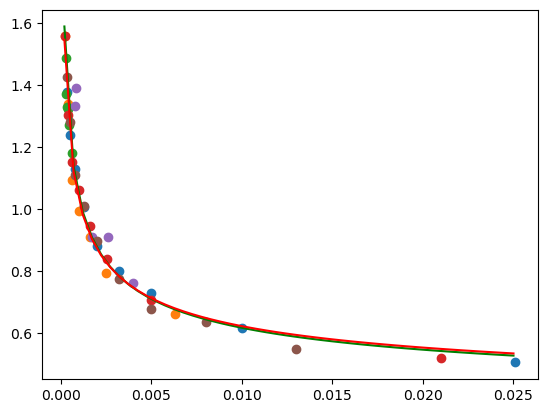

In [259]:
for D in data:
    plt.scatter(D["x"], D["y"])

xvals = np.linspace(2e-4,0.025,50)
plt.plot(xvals, F2(xvals, params), color='green')
plt.plot(xvals, F2(xvals, initParams), color='red')

### Uncertainty estimation via the Hessian matrix method ###

In [260]:
H = hessian(costfunc1D, None, params.flatten())
l, P = np.linalg.eig(H)
T = 0.0001
M = np.array([T/np.sqrt(np.abs(l))[i] * P[:,i] for i in range(len(l))]).T #Matrix of parameter uncertainty vectors, \Delta a

#x, params, index of the row of parameters to evaluate the central f at
def Del_f(x, params, i):
    f_0 = f(x, params[i])
    params = params.flatten()
    diff_plus = []
    diff_min = []

    for k in range(len(params)):
        f_p = f(x, (params.copy() + M[:,k]).reshape((4,4))[i])
        f_m = f(x, (params.copy() - M[:,k]).reshape((4,4))[i])
        diff_p = np.maximum.reduce([f_p - f_0, f_m - f_0, np.zeros_like(f_0)])
        diff_m = np.maximum.reduce([f_0 - f_p, f_0 - f_m, np.zeros_like(f_0)])
        diff_plus.append(diff_p)
        diff_min.append(diff_m)
    
    diff_p2 = [diff**2 for diff in diff_plus]
    diff_m2 = [diff**2 for diff in diff_min]
    Df_plus = np.sqrt(np.sum(diff_p2, axis=0))
    Df_min = np.sqrt(np.sum(diff_m2, axis=0))
    return Df_plus, -Df_min

def xf(x, params, Del_f = 0):
    return x*f(x, params) + Del_f

def xs(x, params):
    s_0 = (lambda xval, p: kappa*(f(xval, p[1])+f(xval, p[3]))/2)(x, params)
    Du_plus, Du_min = Del_f(x, params, 1)
    Dd_plus, Dd_min = Del_f(x, params, 3)
    Ds_plus = np.sqrt(Du_plus**2 + Dd_plus**2)
    Ds_min = np.sqrt(Du_min**2 + Dd_min**2)
    lb = x*s_0 - Ds_min
    ub = x*s_0 + Ds_plus

    return x*s_0, lb, ub

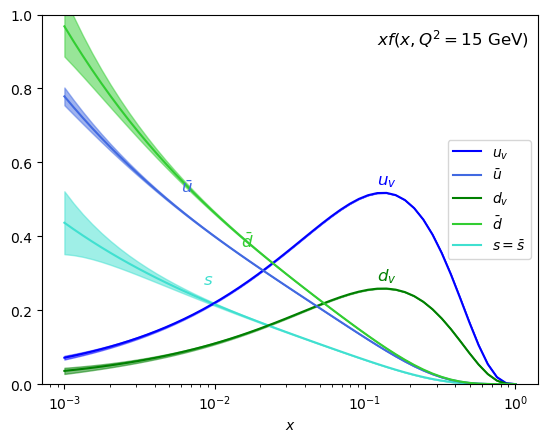

In [261]:
x = np.geomspace(1e-3,1)
colors = ["blue", "royalblue", "green", "limegreen"]
labels = [r"$u_v$", r"$\bar{u}$", r"$d_v$", r"$\bar{d}$"]

s, s_lb, s_ub = xs(x, params)
plt.fill_between(x, s_lb, s_ub, color="turquoise", alpha=0.5)
plt.plot(x, s, color="turquoise", label=r"$s=\bar{s}$")

for i in [0,2,1,3]:
    Df_plus, Df_min = Del_f(x, params, i)
    ub = xf(x, params[i], Df_plus)
    lb = xf(x, params[i], Df_min)
    plt.fill_between(x, lb, ub, color=colors[i], alpha=0.5)

for i in [0, 2, 1, 3]:
    plt.plot(x, xf(x, params[i]), color=colors[i], label=labels[i])

plt.semilogx()
plt.ylim((0,1))
plt.xlabel(r"$x$")
plt.text(1.2e-1, 0.92, r"$xf(x,Q^2=15\text{ GeV})$", fontsize=12)

plt.text(1.2e-1, 0.54, r"$u_v$", color=colors[0], fontsize=12)
plt.text(6e-3, 0.52, r"$\bar{u}$", color=colors[1], fontsize=12)
plt.text(1.2e-1, 0.28, r"$d_v$", color=colors[2], fontsize=12)
plt.text(1.5e-2, 0.37, r"$\bar{d}$", color=colors[3], fontsize=12)
plt.text(8.4e-3, 0.27, r"$s$", color="turquoise", fontsize=12)

handles, labels = plt.gca().get_legend_handles_labels()
order = [1, 3, 2, 4, 0] 
plt.legend([handles[i] for i in order], [labels[i] for i in order])